In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/justmarkham/DAT8/master/data/Advertising.csv"

df = pd.read_csv(url)

# Remove an unnecessary index column if present
df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

print("Dataset loaded successfully!")
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset shape:", df.shape)

HTTPError: HTTP Error 404: Not Found

In [3]:
url = "https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv"

df = pd.read_csv(url)

df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

print("Dataset loaded successfully!")
print("\nFirst 5 rows:")
print(df.head())

print("\nDataset shape:", df.shape)

Dataset loaded successfully!

First 5 rows:
      TV  radio  newspaper  sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9

Dataset shape: (200, 4)


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.datasets import fetch_openml

data = fetch_openml(name="Advertising", version=1, as_frame=True)

df = data.frame

print("Dataset loaded successfully!")
print(df.head())
print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

OpenMLError: Dataset advertising with version 1 not found.

In [5]:
import pandas as pd

url = "https://raw.githubusercontent.com/selva86/datasets/master/Advertising.csv"

df = pd.read_csv(url)

df = df.drop(columns=["Unnamed: 0"], errors="ignore")

print("Dataset loaded successfully!")
print(df.head())
print("\nDataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())

Dataset loaded successfully!
      TV  radio  newspaper  sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9

Dataset shape: (200, 4)

Column names: ['TV', 'radio', 'newspaper', 'sales']


In [6]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
print(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   radio      200 non-null    float64
 2   newspaper  200 non-null    float64
 3   sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB

Missing Values:
TV           0
radio        0
newspaper    0
sales        0
dtype: int64

Duplicate Rows:
0

Statistical Summary:
               TV       radio   newspaper       sales
count  200.000000  200.000000  200.000000  200.000000
mean   147.042500   23.264000   30.554000   14.022500
std     85.854236   14.846809   21.778621    5.217457
min      0.700000    0.000000    0.300000    1.600000
25%     74.375000    9.975000   12.750000   10.375000
50%    149.750000   22.900000   25.750000   12.900000
75%    218.825000   36.525000   45.100000   17.400000
max    296.400000   49.600000  1

In [7]:
# Sales distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Sales", kde=True)
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

# Advertising spending compared with sales
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.scatterplot(data=df, x="TV", y="Sales", ax=axes[0])
axes[0].set_title("TV Advertising vs Sales")

sns.scatterplot(data=df, x="Radio", y="Sales", ax=axes[1])
axes[1].set_title("Radio Advertising vs Sales")

sns.scatterplot(data=df, x="Newspaper", y="Sales", ax=axes[2])
axes[2].set_title("Newspaper Advertising vs Sales")

plt.tight_layout()
plt.show()

ValueError: Could not interpret value `Sales` for `x`. An entry with this name does not appear in `data`.

<Figure size 700x400 with 0 Axes>

In [8]:
print(df.columns.tolist())

['TV', 'radio', 'newspaper', 'sales']


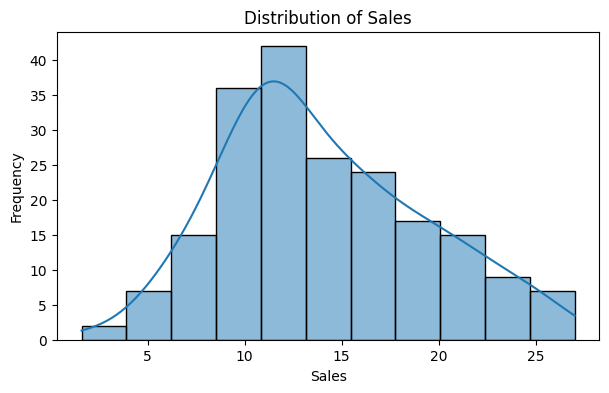

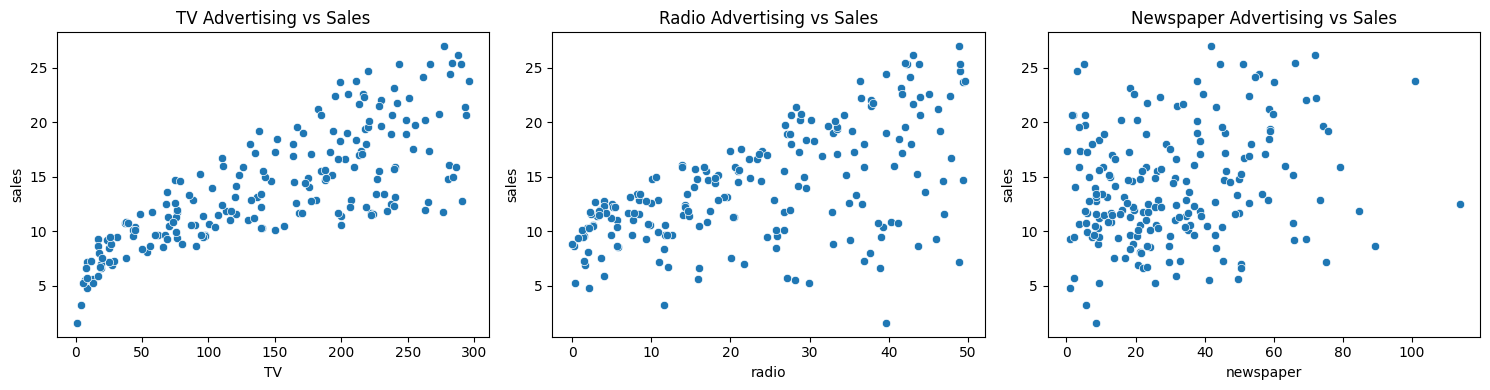

In [9]:
# Sales distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="sales", kde=True)
plt.title("Distribution of Sales")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

# Advertising spending compared with sales
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.scatterplot(data=df, x="TV", y="sales", ax=axes[0])
axes[0].set_title("TV Advertising vs Sales")

sns.scatterplot(data=df, x="radio", y="sales", ax=axes[1])
axes[1].set_title("Radio Advertising vs Sales")

sns.scatterplot(data=df, x="newspaper", y="sales", ax=axes[2])
axes[2].set_title("Newspaper Advertising vs Sales")

plt.tight_layout()
plt.show()

Correlation with Sales:
sales        1.000000
TV           0.782224
radio        0.576223
newspaper    0.228299
Name: sales, dtype: float64


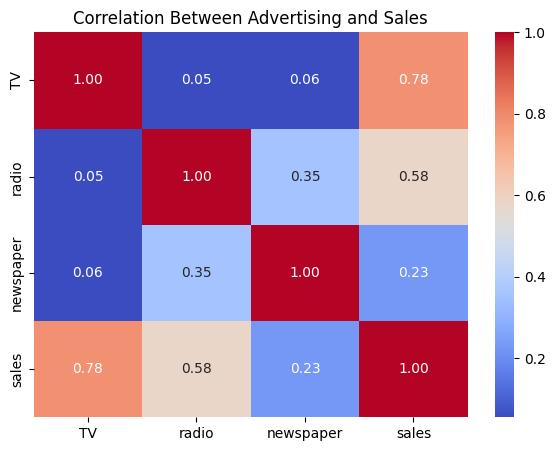

In [10]:
# Calculate correlations
correlation = df.corr(numeric_only=True)

# Display correlation values
print("Correlation with Sales:")
print(correlation["sales"].sort_values(ascending=False))

# Create heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Advertising and Sales")
plt.show()

In [11]:
# Input features: advertising expenses
X = df[["TV", "radio", "newspaper"]]

# Target: sales to predict
y = df["sales"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Data preparation completed!")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Input features:", X.columns.tolist())

Data preparation completed!
Training records: 160
Testing records: 40
Input features: ['TV', 'radio', 'newspaper']


In [12]:
# Create the Linear Regression model
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train, y_train)

# Predict sales for test data
lr_predictions = lr_model.predict(X_test)

print("Linear Regression model trained successfully!")
print("\nFirst 10 actual sales values:")
print(y_test.head(10).values)

print("\nFirst 10 predicted sales values:")
print(lr_predictions[:10])

Linear Regression model trained successfully!

First 10 actual sales values:
[16.9 22.4 21.4  7.3 24.7 12.6 22.3  8.4 11.5 14.9]

First 10 predicted sales values:
[16.4080242  20.88988209 21.55384318 10.60850256 22.11237326 13.10559172
 21.05719192  7.46101034 13.60634581 15.15506967]


In [13]:
# Create the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict sales for test data
rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")
print("\nFirst 10 predicted sales values:")
print(rf_predictions[:10])

Random Forest model trained successfully!

First 10 predicted sales values:
[17.698 21.804 20.628  6.793 22.927 13.379 22.376  9.688 11.826 15.54 ]


In [14]:
# Evaluate Linear Regression
lr_mae = mean_absolute_error(y_test, lr_predictions)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_predictions))
lr_r2 = r2_score(y_test, lr_predictions)

# Evaluate Random Forest
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

# Display comparison
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [lr_mae, rf_mae],
    "RMSE": [lr_rmse, rf_rmse],
    "R2 Score": [lr_r2, rf_r2]
})

print(results.round(3).to_string(index=False))

            Model   MAE  RMSE  R2 Score
Linear Regression 1.461 1.782     0.899
    Random Forest 0.620 0.769     0.981


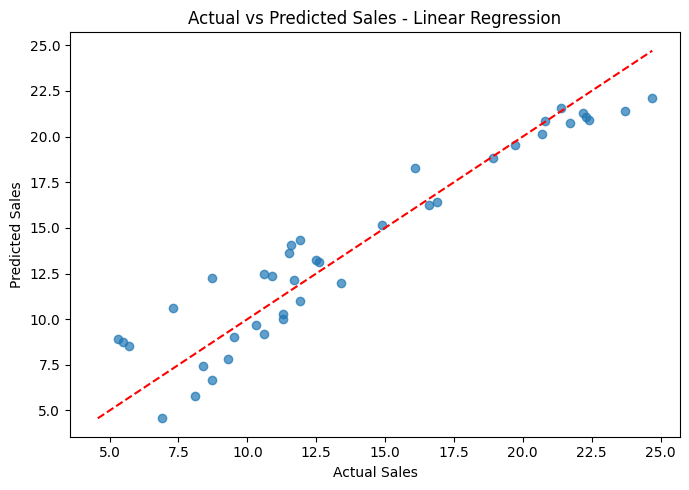

In [15]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, lr_predictions, alpha=0.7)

# Reference line for perfect predictions
minimum = min(y_test.min(), lr_predictions.min())
maximum = max(y_test.max(), lr_predictions.max())

plt.plot([minimum, maximum], [minimum, maximum], "r--")

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales - Linear Regression")
plt.tight_layout()
plt.show()

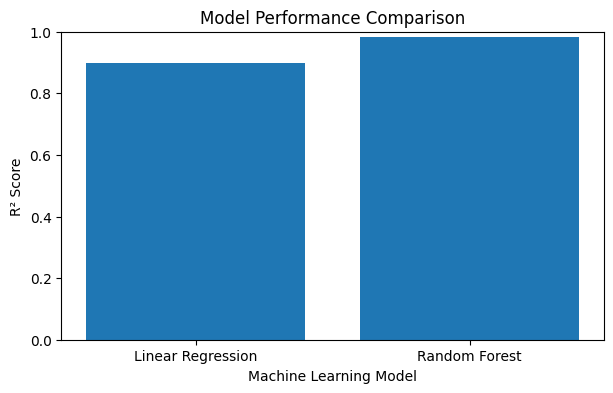

In [16]:
plt.figure(figsize=(7, 4))

plt.bar(results["Model"], results["R2 Score"])

plt.title("Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score")
plt.ylim(0, 1)
plt.show()

In [17]:
# Enter advertising expenses
tv = 150.0
radio = 25.0
newspaper = 20.0

# Prepare the input in the correct format
new_data = pd.DataFrame({
    "TV": [tv],
    "radio": [radio],
    "newspaper": [newspaper]
})

# Predict sales using both models
lr_sales = lr_model.predict(new_data)[0]
rf_sales = rf_model.predict(new_data)[0]

print("Advertising Expenses:")
print("TV:", tv)
print("Radio:", radio)
print("Newspaper:", newspaper)

print("\nPredicted Sales:")
print("Linear Regression:", round(lr_sales, 2))
print("Random Forest:", round(rf_sales, 2))

Advertising Expenses:
TV: 150.0
Radio: 25.0
Newspaper: 20.0

Predicted Sales:
Linear Regression: 14.47
Random Forest: 15.15


In [18]:
# Select the model with the higher R2 score
if lr_r2 >= rf_r2:
    best_model = lr_model
    best_model_name = "Linear Regression"
    best_r2 = lr_r2
else:
    best_model = rf_model
    best_model_name = "Random Forest"
    best_r2 = rf_r2

print("SALES PREDICTION PROJECT RESULTS")
print("--------------------------------")
print("Best Model:", best_model_name)
print("Best R2 Score:", round(best_r2, 3))
print("Linear Regression MAE:", round(lr_mae, 3))
print("Random Forest MAE:", round(rf_mae, 3))
print("\nProject completed successfully!")

SALES PREDICTION PROJECT RESULTS
--------------------------------
Best Model: Random Forest
Best R2 Score: 0.981
Linear Regression MAE: 1.461
Random Forest MAE: 0.62

Project completed successfully!
